# Banking Fraud Detection & Financial Risk Analytics

**Initial Dataset Profile and Basic Quality Checks**

**Objective:** Inspect the dataset size, missing values, and available transaction types using chunk-based processing.

**Why:** To understand the dataset's basic structure and identify missing data before detailed validation.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\Swathi\OneDrive\Desktop\Projects\Banking_Fraud_Analytics\Raw_Data\PS_20174392719_1491204439457_log.csv"

total_rows = 0
missing_counts = None
transaction_types = set()

for chunk in pd.read_csv(file_path, chunksize=100_000):
    total_rows += len(chunk)

    chunk_missing = chunk.isna().sum()
    missing_counts = (chunk_missing if missing_counts is None else missing_counts + chunk_missing)

    transaction_types.update(chunk["type"].dropna().unique())

print("TOTAL ROWS:", f"{total_rows:,}")
print("\nMISSING VALUES BY COLUMN:")
print(missing_counts)
print("\nTRANSACTION TYPES:")
print(sorted(transaction_types))


TOTAL ROWS: 6,362,620

MISSING VALUES BY COLUMN:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

TRANSACTION TYPES:
['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']


### Invalid Values and Negative Balance Validation

**Objective:** Check for negative or zero transaction amounts, negative simulation steps, invalid fraud labels, and negative account balances.

**Why:** To identify values that may need further investigation before analysis.

In [3]:
total_rows = 0
negative_amounts = 0
zero_amounts = 0
negative_steps = 0
invalid_isfraud = 0
invalid_flaggedfraud = 0

balance_columns = ["oldbalanceOrg", "newbalanceOrig","oldbalanceDest", "newbalanceDest"]
negative_balances = dict.fromkeys(balance_columns, 0)

for chunk in pd.read_csv(file_path, chunksize=100_000):
    total_rows += len(chunk)

    negative_amounts += (chunk["amount"] < 0).sum()
    zero_amounts += (chunk["amount"] == 0).sum()
    negative_steps += (chunk["step"] < 0).sum()

    invalid_isfraud += (~chunk["isFraud"].isin([0, 1])).sum()
    invalid_flaggedfraud += (~chunk["isFlaggedFraud"].isin([0, 1])).sum()

    for col in balance_columns:
        negative_balances[col] += (chunk[col] < 0).sum()

print("TOTAL ROWS:", f"{total_rows:,}")
print("NEGATIVE AMOUNTS:", negative_amounts)
print("ZERO AMOUNTS:", zero_amounts)
print("NEGATIVE STEPS:", negative_steps)
print("INVALID isFraud VALUES:", invalid_isfraud)
print("INVALID isFlaggedFraud VALUES:", invalid_flaggedfraud)

print("\nNEGATIVE BALANCE COUNTS:")
for col, count in negative_balances.items():
    print(f"{col}: {count}")


TOTAL ROWS: 6,362,620
NEGATIVE AMOUNTS: 0
ZERO AMOUNTS: 16
NEGATIVE STEPS: 0
INVALID isFraud VALUES: 0
INVALID isFlaggedFraud VALUES: 0

NEGATIVE BALANCE COUNTS:
oldbalanceOrg: 0
newbalanceOrig: 0
oldbalanceDest: 0
newbalanceDest: 0


### Investigation of Zero-Amount Transactions

**Objective:** Examine the transaction type, fraud labels, and account balances of zero-amount records.

**Why:** Zero-amount records may be unusual, but they should be investigated before deciding whether they are invalid.

In [4]:
zero_amount_parts = []

for chunk in pd.read_csv(file_path, chunksize=100_000):
    zero_rows = chunk.loc[chunk["amount"] == 0]

    if not zero_rows.empty:
        zero_amount_parts.append(zero_rows)

if zero_amount_parts:
    zero_df = pd.concat(zero_amount_parts, ignore_index=True)

    print("ZERO-AMOUNT TRANSACTIONS:", len(zero_df))
    print("\nTRANSACTION TYPES:")
    print(zero_df["type"].value_counts(dropna=False))

    print("\nFRAUD LABEL COUNTS:")
    print(zero_df["isFraud"].value_counts(dropna=False))

    print("\nFLAGGED-FRAUD LABEL COUNTS:")
    print(zero_df["isFlaggedFraud"].value_counts(dropna=False))

    print("\nZERO-AMOUNT RECORDS:")
    print(zero_df.to_string(index=False))
else:
    print("No zero-amount transactions found.")


ZERO-AMOUNT TRANSACTIONS: 16

TRANSACTION TYPES:
type
CASH_OUT    16
Name: count, dtype: int64

FRAUD LABEL COUNTS:
isFraud
1    16
Name: count, dtype: int64

FLAGGED-FRAUD LABEL COUNTS:
isFlaggedFraud
0    16
Name: count, dtype: int64

ZERO-AMOUNT RECORDS:
 step     type  amount    nameOrig  oldbalanceOrg  newbalanceOrig    nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud
  212 CASH_OUT     0.0 C1510987794            0.0             0.0 C1696624817            0.00            0.00        1               0
  250 CASH_OUT     0.0  C521393327            0.0             0.0  C480398193            0.00            0.00        1               0
  279 CASH_OUT     0.0  C539112012            0.0             0.0 C1106468520       538547.63       538547.63        1               0
  387 CASH_OUT     0.0 C1294472700            0.0             0.0 C1325541393      7970766.57      7970766.57        1               0
  425 CASH_OUT     0.0  C832555372            0.0             0.0 C

### Overall Origin Balance Consistency Check

**Objective:** Compare the expected origin balance (`oldbalanceOrg - amount`) with the recorded `newbalanceOrig` for TRANSFER and CASH_OUT transactions.

**Why:** To identify records where the observed origin balance does not match this simple expected-balance rule.

**Validation tolerance:** Differences greater than 0.01 are counted as mismatches. A mismatch is a finding for investigation, not automatically a data error.

In [5]:
eligible_rows = 0
origin_balance_mismatches = 0

for chunk in pd.read_csv(file_path, chunksize=100_000):
    outgoing = chunk.loc[chunk["type"].isin(["TRANSFER", "CASH_OUT"])]

    expected_balance = outgoing["oldbalanceOrg"] - outgoing["amount"]

    mismatch = ((outgoing["newbalanceOrig"] - expected_balance).abs() > 0.01)

    eligible_rows += len(outgoing)
    origin_balance_mismatches += mismatch.sum()

print("TRANSFER/CASH_OUT ROWS CHECKED:", f"{eligible_rows:,}")
print("ORIGIN BALANCE MISMATCHES:", f"{origin_balance_mismatches:,}")
print("MISMATCH RATE (%):",round(origin_balance_mismatches / eligible_rows * 100, 2))

TRANSFER/CASH_OUT ROWS CHECKED: 2,770,409
ORIGIN BALANCE MISMATCHES: 2,500,051
MISMATCH RATE (%): 90.24


### Origin Balance Mismatches by Transaction Type and Fraud Label

**Objective:** Summarize the number and percentage of origin balance mismatches by transaction type and fraud label.

**Why:** To determine whether mismatch patterns differ between fraud-labelled and non-fraud-labelled records.

In [6]:
summary_parts = []

for chunk in pd.read_csv(file_path, chunksize=100_000):
    outgoing = chunk.loc[chunk["type"].isin(["TRANSFER", "CASH_OUT"])].copy()

    expected_balance = outgoing["oldbalanceOrg"] - outgoing["amount"]

    outgoing["balance_mismatch"] = ((outgoing["newbalanceOrig"] - expected_balance).abs() > 0.01)

    summary = outgoing.groupby(["type", "isFraud"]).agg(total_transactions=("balance_mismatch", "size"),mismatches=("balance_mismatch", "sum"))

    summary_parts.append(summary)

result_df = pd.concat(summary_parts).groupby(level=[0, 1]).sum()

result_df["mismatch_percent"] = (result_df["mismatches"] / result_df["total_transactions"] * 100).round(2)

print(result_df.reset_index().to_string(index=False))


    type  isFraud  total_transactions  mismatches  mismatch_percent
CASH_OUT        0             2233384     1991245             89.16
CASH_OUT        1                4116          24              0.58
TRANSFER        0              528812      508761             96.21
TRANSFER        1                4097          21              0.51


### Sample Inspection of Origin Balance Mismatches

**Objective:** Display up to 10 non-fraud-labelled TRANSFER or CASH_OUT records that fail the origin balance consistency check.

**Why:** To inspect examples and understand the mismatch pattern before deciding whether any further investigation is needed.

In [7]:
sample_parts = []
sample_count = 0

columns_to_display = ["type", "amount", "oldbalanceOrg","newbalanceOrig", "isFraud"]

for chunk in pd.read_csv(file_path, chunksize=100_000):
    outgoing = chunk.loc[chunk["type"].isin(["TRANSFER", "CASH_OUT"])& (chunk["isFraud"] == 0)]

    expected_balance = outgoing["oldbalanceOrg"] - outgoing["amount"]

    mismatch = ((outgoing["newbalanceOrig"] - expected_balance).abs() > 0.01)

    sample = outgoing.loc[mismatch, columns_to_display].head(10 - sample_count)

    if not sample.empty:
        sample_parts.append(sample)
        sample_count += len(sample)

    if sample_count >= 10:
        break

if sample_parts:
    sample_df = pd.concat(sample_parts, ignore_index=True)
    print(sample_df.to_string(index=False))
else:
    print("No mismatches found in the sample.")


    type    amount  oldbalanceOrg  newbalanceOrig  isFraud
CASH_OUT 229133.94       15325.00             0.0        0
TRANSFER 215310.30         705.00             0.0        0
TRANSFER 311685.89       10835.00             0.0        0
CASH_OUT 110414.71       26845.41             0.0        0
CASH_OUT  56953.90        1942.02             0.0        0
CASH_OUT   5346.89           0.00             0.0        0
CASH_OUT  23261.30       20411.53             0.0        0
CASH_OUT  82940.31        3017.87             0.0        0
CASH_OUT  94253.33       25203.05             0.0        0
TRANSFER  42712.39       10363.39             0.0        0


### Overall Unchanged Account Balance Analysis

**Objective:** Count transactions where the origin or destination balance remains unchanged before and after the transaction.

**Why:** To identify balance patterns that may depend on transaction type or dataset simulation rules.

In [8]:
total_rows = 0
same_origin_balance = 0
same_destination_balance = 0

for chunk in pd.read_csv(file_path, chunksize=100_000):
    total_rows += len(chunk)

    same_origin_balance += (chunk["oldbalanceOrg"] == chunk["newbalanceOrig"]).sum()

    same_destination_balance += (chunk["oldbalanceDest"] == chunk["newbalanceDest"]).sum()

print("TOTAL ROWS:", f"{total_rows:,}")
print("ORIGIN BALANCE UNCHANGED:", f"{same_origin_balance:,}")
print("DESTINATION BALANCE UNCHANGED:", f"{same_destination_balance:,}")

print("ORIGIN UNCHANGED (%):",round(same_origin_balance / total_rows * 100, 2))
print("DESTINATION UNCHANGED (%):",round(same_destination_balance / total_rows * 100, 2))

TOTAL ROWS: 6,362,620
ORIGIN BALANCE UNCHANGED: 2,089,037
DESTINATION BALANCE UNCHANGED: 2,317,292
ORIGIN UNCHANGED (%): 32.83
DESTINATION UNCHANGED (%): 36.42


### Unchanged Account Balances by Transaction Type

**Objective:** Calculate unchanged origin and destination balance counts and percentages for each transaction type.

**Why:** To compare balance behaviour across transaction categories and identify patterns for further analysis.

In [9]:
summary_parts = []

for chunk in pd.read_csv(file_path, chunksize=100_000):
    chunk["origin_unchanged"] = (chunk["oldbalanceOrg"] == chunk["newbalanceOrig"])
    chunk["destination_unchanged"] = (chunk["oldbalanceDest"] == chunk["newbalanceDest"])

    summary = chunk.groupby("type").agg(total_transactions=("type", "size"),origin_unchanged=("origin_unchanged", "sum"),destination_unchanged=("destination_unchanged", "sum"))

    summary_parts.append(summary)

final_summary = pd.concat(summary_parts).groupby(level=0).sum()

final_summary["origin_unchanged_pct"] = (final_summary["origin_unchanged"]/ final_summary["total_transactions"] * 100).round(2)

final_summary["destination_unchanged_pct"] = (final_summary["destination_unchanged"]/ final_summary["total_transactions"] * 100).round(2)

print(final_summary.to_string())

          total_transactions  origin_unchanged  destination_unchanged  origin_unchanged_pct  destination_unchanged_pct
type                                                                                                                  
CASH_IN              1399284                33                 160005                  0.00                      11.43
CASH_OUT             2237500           1025801                   1618                 45.85                       0.07
DEBIT                  41432              6158                      0                 14.86                       0.00
PAYMENT              2151495            774245                2151495                 35.99                     100.00
TRANSFER              532909            282800                   4174                 53.07                       0.78


### Fraud and Flagged-Fraud Label Distribution

**Objective:** Calculate the count and percentage distribution of `isFraud` and `isFlaggedFraud` labels.

**Why:** To understand class imbalance and compare the dataset's fraud labels with its separate flagged-fraud indicator.

In [10]:
fraud_counts = {0: 0, 1: 0}
flagged_counts = {0: 0, 1: 0}
total_rows = 0

for chunk in pd.read_csv(file_path, chunksize=100_000):
    total_rows += len(chunk)

    for label, count in chunk["isFraud"].value_counts().items():
        fraud_counts[int(label)] += int(count)

    for label, count in chunk["isFlaggedFraud"].value_counts().items():
        flagged_counts[int(label)] += int(count)

print("TOTAL TRANSACTIONS:", f"{total_rows:,}")

print("\nFRAUD LABEL DISTRIBUTION:")
for label, count in sorted(fraud_counts.items()):
    print(f"isFraud={label}: {count:,} ({count / total_rows * 100:.4f}%)")

print("\nFLAGGED-FRAUD LABEL DISTRIBUTION:")
for label, count in sorted(flagged_counts.items()):
    print(f"isFlaggedFraud={label}: {count:,} ({count / total_rows * 100:.4f}%)")

TOTAL TRANSACTIONS: 6,362,620

FRAUD LABEL DISTRIBUTION:
isFraud=0: 6,354,407 (99.8709%)
isFraud=1: 8,213 (0.1291%)

FLAGGED-FRAUD LABEL DISTRIBUTION:
isFlaggedFraud=0: 6,362,604 (99.9997%)
isFlaggedFraud=1: 16 (0.0003%)


### Fraud Rate Analysis by Transaction Type

**Objective:** Calculate total transactions, fraud-labelled transactions, and fraud rate for each transaction type.

**Why:** To compare fraud-labelled transaction volume and rate across transaction categories.

**Formula:** Fraud rate (%) = Fraud-labelled transactions ÷ Total transactions × 100.

In [11]:
summary_parts = []

for chunk in pd.read_csv(file_path, chunksize=100_000):
    summary = chunk.groupby("type").agg(total_transactions=("isFraud", "size"),fraud_transactions=("isFraud", "sum"))

    summary_parts.append(summary)

final_summary = pd.concat(summary_parts).groupby(level=0).sum()

final_summary["fraud_rate_pct"] = ( final_summary["fraud_transactions"]/ final_summary["total_transactions"] * 100).round(4)

final_summary = final_summary.sort_values("fraud_rate_pct", ascending=False)

print(final_summary.to_string())

          total_transactions  fraud_transactions  fraud_rate_pct
type                                                            
TRANSFER              532909                4097          0.7688
CASH_OUT             2237500                4116          0.1840
CASH_IN              1399284                   0          0.0000
DEBIT                  41432                   0          0.0000
PAYMENT              2151495                   0          0.0000


**Fraud Distribution Analysis by Transaction Type Using Python and Matplotlib**

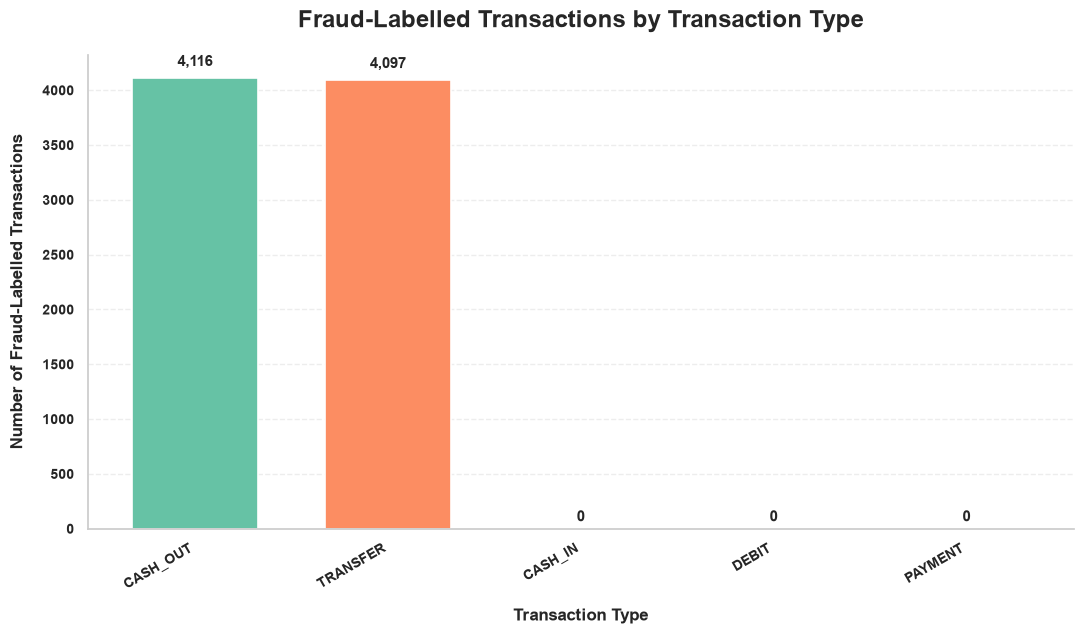

In [12]:
plt.rcParams["font.family"] = "DejaVu Sans"
sns.set_theme(style="whitegrid", context="notebook")

chart_data = final_summary["fraud_transactions"].sort_values(ascending=False)

palette = sns.color_palette("Set2", n_colors=len(chart_data))

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(chart_data.index,chart_data.values,color=palette,width=0.65,edgecolor="white",linewidth=1.2)

ax.set_title("Fraud-Labelled Transactions by Transaction Type",fontsize=17,fontweight="bold",pad=20)

ax.set_xlabel("Transaction Type",fontsize=12,fontweight="bold",labelpad=12)

ax.set_ylabel("Number of Fraud-Labelled Transactions",fontsize=12,fontweight="bold",labelpad=12)

ax.tick_params(axis="both", labelsize=10)
plt.setp(ax.get_xticklabels(),rotation=30,ha="right",fontweight="bold")

plt.setp(ax.get_yticklabels(), fontweight="bold")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{int(height):,}",xy=(bar.get_x() + bar.get_width() / 2, height),xytext=(0, 6 if height > 0 else 3),textcoords="offset points",ha="center",va="bottom",fontsize=11,fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


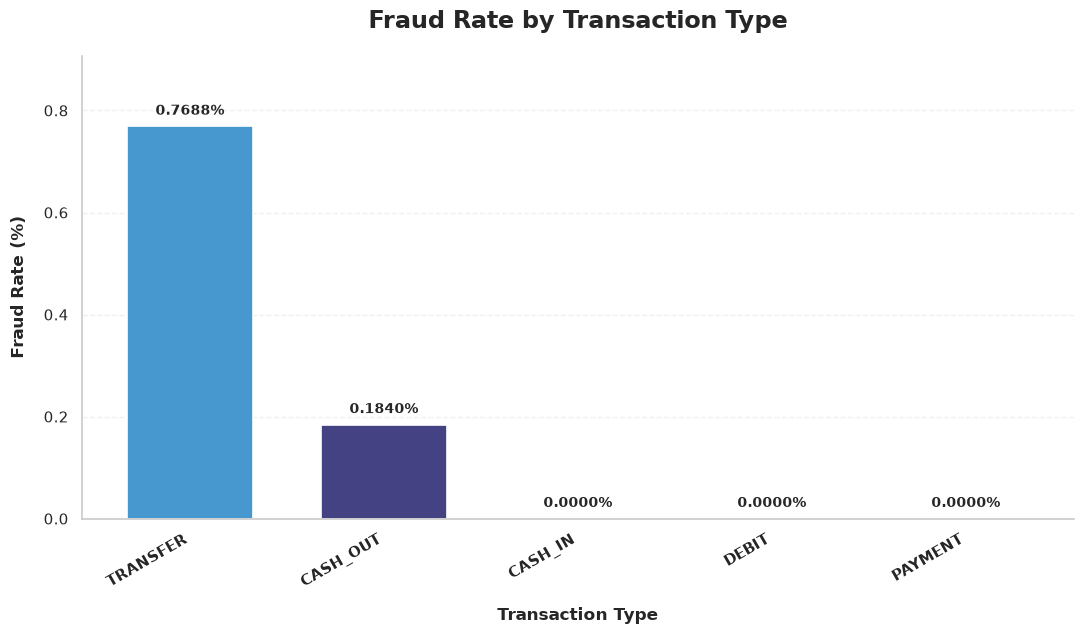

In [26]:
rate_data = final_summary["fraud_rate_pct"].sort_values(ascending=False)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "DejaVu Sans"

fig, ax = plt.subplots(figsize=(11, 6.5))

palette = sns.color_palette("icefire", n_colors=len(rate_data))
bars = ax.bar(rate_data.index,rate_data.values,color=palette,width=0.65,edgecolor="white",linewidth=1.2)

ax.set_title("Fraud Rate by Transaction Type",fontsize=17,fontweight="bold",pad=20)
ax.set_xlabel("Transaction Type",fontsize=12,fontweight="bold",labelpad=12)
ax.set_ylabel("Fraud Rate (%)",fontsize=12,fontweight="bold",labelpad=12)

plt.setp(ax.get_xticklabels(),rotation=30,ha="right",fontweight="bold")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.4f}%",xy=(bar.get_x() + bar.get_width() / 2, height),xytext=(0, 6),textcoords="offset points",ha="center",va="bottom",fontsize=10,fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.set_ylim(0, max(rate_data.max() * 1.18, 0.01))
plt.tight_layout()
plt.show()


**Comparative Analysis of Fraud and Non-Fraud Transaction Amounts**

In [ ]:
count_by_label = {0: 0, 1: 0}
sum_by_label = {0: 0.0, 1: 0.0}
min_by_label = {0: float("inf"), 1: float("inf")}
max_by_label = {0: float("-inf"), 1: float("-inf")}
amounts_by_label = {0: [], 1: []}

for chunk in pd.read_csv(file_path,usecols=["amount", "isFraud"],chunksize=100_000):
    for label in [0, 1]:
        amounts = chunk.loc[chunk["isFraud"] == label, "amount"]
        if not amounts.empty:
            count_by_label[label] += len(amounts)
            sum_by_label[label] += amounts.sum()
            min_by_label[label] = min(min_by_label[label], amounts.min())
            max_by_label[label] = max(max_by_label[label], amounts.max())
            amounts_by_label[label].extend(amounts.tolist())

results = []

for label in [0, 1]:
    values = amounts_by_label[label]
    results.append({"isFraud": label,"total_transactions": count_by_label[label],"average_amount": sum_by_label[label] / count_by_label[label],"median_amount": pd.Series(values).median(),"minimum_amount": min_by_label[label],"maximum_amount": max_by_label[label],"total_transaction_amount": sum_by_label[label]})

amount_summary = pd.DataFrame(results).set_index("isFraud")
print(amount_summary.round(2).to_string())

         total_transactions  average_amount  median_amount  minimum_amount  maximum_amount  total_transaction_amount
isFraud                                                                                                             
0                   6354407       178197.04       74684.72            0.01     92445516.64              1.132337e+12
1                      8213      1467967.30      441423.44            0.00     10000000.00              1.205642e+10


**Analyze fraud against flagged transactions**

In [ ]:
cross_tab_parts = []

for chunk in pd.read_csv(file_path,usecols=["isFraud", "isFlaggedFraud"],chunksize=100_000):
    table = pd.crosstab(chunk["isFraud"],chunk["isFlaggedFraud"])
    cross_tab_parts.append(table)

fraud_flag_summary = (pd.concat(cross_tab_parts).groupby(level=0).sum())
fraud_flag_summary = fraud_flag_summary.reindex(index=[0, 1],columns=[0, 1],fill_value=0)
fraud_flag_summary.index.name = "Actual_Fraud_Label"
fraud_flag_summary.columns.name = "System_Flag"
print("Fraud Label vs System Flag")
print(fraud_flag_summary.to_string())
print("\nInterpretation:")
print("Rows: dataset fraud label (0 = non-fraud, 1 = fraud)")
print("Columns: system flag (0 = not flagged, 1 = flagged)")


Fraud Label vs System Flag
System_Flag               0     1
Actual_Fraud_Label               
0                   6354407   0.0
1                      8197  16.0

Interpretation:
Rows: dataset fraud label (0 = non-fraud, 1 = fraud)
Columns: system flag (0 = not flagged, 1 = flagged)


**Transaction Amount Analysis by Type**

In [ ]:
summary_parts = []

for chunk in pd.read_csv(file_path,usecols=["type", "amount", "isFraud"],chunksize=100_000):
    summary = chunk.groupby("type").agg(
        total_transactions=("amount", "size"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
        fraud_transactions=("isFraud", "sum")
    )
    summary_parts.append(summary)
amount_summary = (pd.concat(summary_parts).groupby(level=0).agg({"total_transactions": "sum","total_amount": "sum","fraud_transactions": "sum"}))
amount_summary["average_amount"] = (amount_summary["total_amount"] /amount_summary["total_transactions"])
amount_summary = amount_summary.sort_values("average_amount",ascending=False)
print(amount_summary.round(2).to_string()) 

          total_transactions  total_amount  fraud_transactions  average_amount
type                                                                          
TRANSFER              532909  4.852920e+11                4097       910647.01
CASH_OUT             2237500  3.944130e+11                4116       176273.96
CASH_IN              1399284  2.363674e+11                   0       168920.24
PAYMENT              2151495  2.809337e+10                   0        13057.60
DEBIT                  41432  2.271992e+08                   0         5483.67


**Compare fraud and non-fraud transaction types**

In [ ]:
summary_parts = []

for chunk in pd.read_csv(file_path,usecols=["type", "isFraud"],chunksize=100_000):
    summary = chunk.groupby("type").agg(total_transactions=("isFraud", "size"),fraud_transactions=("isFraud", "sum"))
    summary_parts.append(summary)

fraud_pattern_summary = (pd.concat(summary_parts).groupby(level=0).sum())
fraud_pattern_summary["non_fraud_transactions"] = (fraud_pattern_summary["total_transactions"]- fraud_pattern_summary["fraud_transactions"])
fraud_pattern_summary["fraud_rate_pct"] = (fraud_pattern_summary["fraud_transactions"]/ fraud_pattern_summary["total_transactions"] * 100).round(4)
print(fraud_pattern_summary.sort_values("fraud_rate_pct", ascending=False).to_string())

          total_transactions  fraud_transactions  non_fraud_transactions  fraud_rate_pct
type                                                                                    
TRANSFER              532909                4097                  528812          0.7688
CASH_OUT             2237500                4116                 2233384          0.1840
CASH_IN              1399284                   0                 1399284          0.0000
DEBIT                  41432                   0                   41432          0.0000
PAYMENT              2151495                   0                 2151495          0.0000


**Explore Origin and Destination Balance Patterns**

In [ ]:
summary_parts = []
columns = ["type","isFraud","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest"]

for chunk in pd.read_csv(file_path,usecols=columns,chunksize=100_000):
    chunk["origin_balance_change"] = (chunk["newbalanceOrig"] - chunk["oldbalanceOrg"])
    chunk["destination_balance_change"] = (chunk["newbalanceDest"] - chunk["oldbalanceDest"])
    summary = chunk.groupby(["type", "isFraud"]).agg(total_transactions=("isFraud", "size"),avg_origin_balance_change=("origin_balance_change", "mean"),avg_destination_balance_change=("destination_balance_change", "mean") )
    summary_parts.append(summary)
combined = pd.concat(summary_parts)

balance_summary = combined.groupby(level=[0, 1]).apply(
    lambda group: pd.Series({
        "total_transactions": group["total_transactions"].sum(),
        "avg_origin_balance_change": (
            group["avg_origin_balance_change"]
            * group["total_transactions"]
        ).sum() / group["total_transactions"].sum(),
        "avg_destination_balance_change": (
            group["avg_destination_balance_change"]
            * group["total_transactions"]
        ).sum() / group["total_transactions"].sum()
    }),
    include_groups=False
)
print(balance_summary.round(2).to_string())

                  total_transactions  avg_origin_balance_change  avg_destination_balance_change
type     isFraud                                                                               
CASH_IN  0                 1399284.0                  168915.20                      -120813.41
CASH_OUT 0                 2233384.0                  -25922.96                       191225.69
         1                    4116.0                -1453796.46                      1464626.42
DEBIT    0                   41432.0                   -3485.69                        19867.70
PAYMENT  0                 2151495.0                   -6378.94                            0.00
TRANSFER 0                  528812.0                  -33178.39                       994585.11
         1                    4097.0                -1460769.62                         2908.03


**Identify Important Fraud Indicators**

In [ ]:
summary_parts = []
columns = ["type","amount","isFraud","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest"]

for chunk in pd.read_csv(file_path,usecols=columns,chunksize=100_000):
    chunk["origin_balance_change"] = (chunk["newbalanceOrig"] - chunk["oldbalanceOrg"])
    chunk["destination_balance_change"] = (chunk["newbalanceDest"] - chunk["oldbalanceDest"])
    summary = chunk.groupby(["isFraud", "type"]).agg(
        transaction_count=("amount", "size"),
        avg_amount=("amount", "mean"),
        avg_origin_change=("origin_balance_change", "mean"),
        avg_destination_change=("destination_balance_change", "mean")
    )
    summary_parts.append(summary)
combined = pd.concat(summary_parts)

weighted_summary = combined.groupby(level=[0, 1]).apply(
    lambda group: pd.Series({
        "transaction_count": group["transaction_count"].sum(),
        "avg_amount": (
            group["avg_amount"] * group["transaction_count"]
        ).sum() / group["transaction_count"].sum(),
        "avg_origin_change": (
            group["avg_origin_change"] * group["transaction_count"]
        ).sum() / group["transaction_count"].sum(),
        "avg_destination_change": (
            group["avg_destination_change"] * group["transaction_count"]
        ).sum() / group["transaction_count"].sum()
    }),
    include_groups=False
)
print(weighted_summary.round(2).to_string())

                  transaction_count  avg_amount  avg_origin_change  avg_destination_change
isFraud type                                                                              
0       CASH_IN           1399284.0   168920.24          168915.20              -120813.41
        CASH_OUT          2233384.0   173917.16          -25922.96               191225.69
        DEBIT               41432.0     5483.67           -3485.69                19867.70
        PAYMENT           2151495.0    13057.60           -6378.94                    0.00
        TRANSFER           528812.0   906229.01          -33178.39               994585.11
1       CASH_OUT             4116.0  1455102.59        -1453796.46              1464626.42
        TRANSFER             4097.0  1480891.67        -1460769.62                 2908.03


**Prepare the Analysis-Ready Dataset**

In [ ]:
from pathlib import Path

file_path = Path(r"C:\Users\Swathi\OneDrive\Desktop\Projects\Banking Fraud Analytics\Raw Data\PS_20174392719_1491204439457_log.csv")

output_path = file_path.parent / "banking_fraud_analysis_ready.csv"

if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found. Please check the path: {file_path}")

chunksize = 100_000
total_rows = 0
first_chunk = True

for chunk in pd.read_csv(file_path, chunksize=chunksize):
    chunk.columns = chunk.columns.str.strip()
    chunk["origin_balance_change"] = (chunk["newbalanceOrig"] - chunk["oldbalanceOrg"])
    chunk["destination_balance_change"] = (chunk["newbalanceDest"] - chunk["oldbalanceDest"])
    chunk.to_csv(output_path,index=False,mode="w" if first_chunk else "a",header=first_chunk)
    total_rows += len(chunk)
    first_chunk = False

print("DATA PREPARATION COMPLETED")
print("-" * 40)
print("Total rows processed:", total_rows)
print("Output file:", output_path)
print("Output file exists:", output_path.exists())
print("New columns added:")
print("1. origin_balance_change")
print("2. destination_balance_change")

DATA PREPARATION COMPLETED
----------------------------------------
Total rows processed: 6362620
Output file: C:\Users\Swathi\OneDrive\Desktop\Projects\Banking Fraud Analytics\Raw Data\banking_fraud_analysis_ready.csv
Output file exists: True
New columns added:
1. origin_balance_change
2. destination_balance_change


**Validate the Analysis-Ready Dataset**

In [ ]:
expected_rows = 6_362_620
total_rows = 0
missing_values = None
fraud_counts = {}
type_counts = {}
invalid_labels = 0
balance_check_errors = 0

required_columns = ["step", "type", "amount", "nameOrig","oldbalanceOrg", "newbalanceOrig", "nameDest","oldbalanceDest", "newbalanceDest","isFraud", "isFlaggedFraud","origin_balance_change", "destination_balance_change"]

if not output_path.exists():
    raise FileNotFoundError(f"File not found: {output_path}")

for chunk in pd.read_csv(output_path, chunksize=100_000):
    total_rows += len(chunk)
    if not set(required_columns).issubset(chunk.columns):
        raise ValueError("One or more required columns are missing.")
    chunk_missing = chunk.isna().sum()
    if missing_values is None:
        missing_values = chunk_missing
    else:
        missing_values = missing_values.add(chunk_missing, fill_value=0)
    invalid_labels += (~chunk["isFraud"].isin([0, 1])).sum()
    invalid_labels += (~chunk["isFlaggedFraud"].isin([0, 1])).sum()
    fraud_counts_chunk = chunk["isFraud"].value_counts()

    for label, count in fraud_counts_chunk.items():
        fraud_counts[label] = fraud_counts.get(label, 0) + count
    type_counts_chunk = chunk["type"].value_counts()

    for transaction_type, count in type_counts_chunk.items():
        type_counts[transaction_type] = (type_counts.get(transaction_type, 0) + count)
    origin_expected = (chunk["newbalanceOrig"] - chunk["oldbalanceOrg"])
    destination_expected = (chunk["newbalanceDest"] - chunk["oldbalanceDest"])

    balance_check_errors += ((chunk["origin_balance_change"] - origin_expected).abs() > 0.01).sum()

    balance_check_errors += ((chunk["destination_balance_change"]- destination_expected).abs() > 0.01).sum()

print("DATASET VALIDATION RESULTS")
print("-" * 40)
print("Expected rows:", expected_rows)
print("Actual rows:", total_rows)
print("Row count matches:", total_rows == expected_rows)
print("\nMissing values by column:")
print(missing_values.astype(int).to_string())
print("\nFraud label counts:")
print(fraud_counts)
print("\nTransaction type counts:")
print(type_counts)
print("\nInvalid fraud/system-flag values:", invalid_labels)
print("Balance-change calculation errors:", balance_check_errors)
print("\nAll required columns present:", True)

DATASET VALIDATION RESULTS
----------------------------------------
Expected rows: 6362620
Actual rows: 6362620
Row count matches: True

Missing values by column:
step                          0
type                          0
amount                        0
nameOrig                      0
oldbalanceOrg                 0
newbalanceOrig                0
nameDest                      0
oldbalanceDest                0
newbalanceDest                0
isFraud                       0
isFlaggedFraud                0
origin_balance_change         0
destination_balance_change    0

Fraud label counts:
{0: 6354407, 1: 8213}

Transaction type counts:
{'PAYMENT': 2151495, 'CASH_OUT': 2237500, 'CASH_IN': 1399284, 'TRANSFER': 532909, 'DEBIT': 41432}

Invalid fraud/system-flag values: 0
Balance-change calculation errors: 0

All required columns present: True
